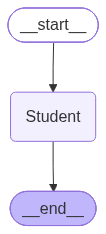

In [17]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END
from IPython.display import Image, display

# 1. State layout definition
class AgentSchema(TypedDict):
    messages : str
    name : str
    dept : str
    year : int

# 2. Functional Node
def student_node(state : AgentSchema) -> AgentSchema:
    """This node takes the input of the student name, dept and year and updates the message."""
    state["messages"] = f"{state['name']} you are doing an amazing job. {state['year']} {state['dept']}"
    return state

# 3. Create graph with SCHEMA class (Must run to update 'app')
graph = StateGraph(AgentSchema)
graph.add_node("Student", student_node)
graph.set_entry_point("Student")
graph.set_finish_point("Student")

app = graph.compile()
display(Image(app.get_graph().draw_mermaid_png()))


In [20]:
result = app.invoke({"name" : "Sri Varshini", "dept" : "CCE", "year" : 4})
print(result["messages"])

Sri Varshini you are doing an amazing job. 4 CCE


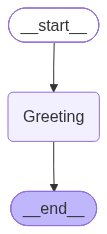

Hii Sri Varshini! Pleased to have you today


In [25]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END
from IPython.display import Image,display

class AgentSchema(TypedDict):
    messages : str

def greet_node(state:AgentSchema)-> AgentSchema:
    state["messages"]  = "Hii " + state["messages"] + "! Pleased to have you today"
    return state

graph = StateGraph(AgentSchema)
graph.add_node("Greeting",greet_node)
graph.set_entry_point("Greeting")
graph.set_finish_point("Greeting")
app = graph.compile()
display(Image(app.get_graph().draw_mermaid_png()))
result = app.invoke({"messages" : "Sri Varshini"})
print(result["messages"])